# 5. Оценка на test, экономика и сегменты

Всё про test посчитано одним запуском `python -m src.evaluate_test` по плану, замороженному до первого обращения
к test (`docs/plan.md`, «Заморозка перед test»). Этот ноутбук только читает `artifacts/test_results.json`.
Сегменты в конце - разведка на valid, test для них не используется.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, models, plots, stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plots.setup()
res = json.loads((models.ARTIFACTS / "test_results.json").read_text())
FINAL = "class_transformation"
ORDER = ["class_transformation", "t_learner", "response", "inverse_response"]
ks = res["ks"]
shares = np.array(res["shares"])
r_grid = np.array(res["r_grid"])
ate = res["ate"]
print(f"test: {res['n']} клиентов, treatment {res['n_treatment']}, control {res['n_control']}")
print(f"ATE_test = {ate * 100:.2f} п.п. ({res['ate_ci'][0] * 100:.2f} ... {res['ate_ci'][1] * 100:.2f}), "
      f"бутстреп B = {res['n_boot']}, seed {res['boot_seed']}")
_, y_v, t_v = models.load("valid")
print(f"ATE_valid = {(y_v[t_v == 1].mean() - y_v[t_v == 0].mean()) * 100:.4f} п.п., ATE_test = {ate * 100:.4f} п.п.")

test: 40008 клиентов, treatment 19996, control 20012
ATE_test = 3.32 п.п. (2.35 ... 4.30), бутстреп B = 1000, seed 42


ATE_valid = 3.3239 п.п., ATE_test = 3.3239 п.п.


ATE_test в точности равен ATE_valid. Это следствие разбиения, а не ошибка: стратификация по treatment x target при
одинаковых размерах valid и test даёт одинаковые числа клиентов в каждой из четырёх ячеек (19 996 / 20 012
клиентов и 12 728 / 12 073 покупателей). Поэтому средний эффект на test не несёт независимой информации, а его интервал
отражает только выборочный шум.

## Метрики на test

Финальная модель - трансформация классов seed 42, остальные строки - бейзлайны. Интервалы - парный бутстреп
внутри групп, «неопределённость оценки на test»; у случайной рассылки интервал Qini - 95% случайных перестановок.

In [2]:
def fmt(v, c, scale=1, digits=3):
    return f"{v * scale:.{digits}f} ({c[0] * scale:.{digits}f} ... {c[1] * scale:.{digits}f})"


rows = []
for m in ORDER:
    r = res["models"][m]
    row = {"модель": plots.MODEL_NAMES[m], "Qini": fmt(r["metrics"]["qini"], r["metrics_ci"]["qini"])}
    for k in ks:
        c = f"uplift@{k:.0%}"
        row[f"доп. на 1000 @{k:.0%}"] = fmt(r["metrics"][c], r["metrics_ci"][c], 1000, 0)
        n_t, n_c = r["counts"][f"{k:.0%}"]
        row[f"n_t/n_c @{k:.0%}"] = f"{n_t}/{n_c}"
    rows.append(row)
q = res["random"]["metrics_ci"]["qini"]
random_row = {"модель": "случайная рассылка", "Qini": f"0 ({q[0]:.3f} ... {q[1]:.3f})"}
for k in ks:
    random_row[f"доп. на 1000 @{k:.0%}"] = fmt(ate, res["ate_ci"], 1000, 0)
    random_row[f"n_t/n_c @{k:.0%}"] = "-"
rows.append(random_row)
pd.DataFrame(rows).set_index("модель")

,Qini,доп. на 1000 @10%,n_t/n_c @10%,доп. на 1000 @20%,n_t/n_c @20%,доп. на 1000 @30%,n_t/n_c @30%
модель,,,,,,,
трансформация классов,0.015 (0.009 ... 0.022),112 (80 ... 142),1987/2013,88 (65 ... 109),3982/4019,62 (45 ... 79),5968/6034
T-learner,0.012 (0.005 ... 0.019),102 (69 ... 129),1974/2026,73 (51 ... 94),3975/4026,53 (34 ... 71),5967/6035
модель отклика,-0.006 (-0.012 ... -0.001),8 (-5 ... 21),1973/2027,14 (3 ... 25),3982/4019,11 (1 ... 23),5972/6030
обратный отклик,0.008 (0.002 ... 0.014),28 (2 ... 57),2000/2000,32 (14 ... 52),4021/3980,38 (22 ... 55),5997/6005
случайная рассылка,0 (-0.006 ... 0.006),33 (24 ... 43),-,33 (24 ... 43),-,33 (24 ... 43),-


In [3]:
rows = []
for name, d in res["differences"].items():
    a, b = name.split(" - ")
    row = {"разность": f"трансформация классов - {plots.MODEL_NAMES.get(b, 'случайная')}"}
    row["Qini"] = fmt(d["qini"]["estimate"], d["qini"]["ci"])
    for k in ks:
        c = f"uplift@{k:.0%}"
        row[f"доп. на 1000 @{k:.0%}"] = fmt(d[c]["estimate"], d[c]["ci"], 1000, 0)
    rows.append(row)
pd.DataFrame(rows).set_index("разность")

,Qini,доп. на 1000 @10%,доп. на 1000 @20%,доп. на 1000 @30%
разность,,,,
трансформация классов - T-learner,0.003 (-0.003 ... 0.009),10 (-20 ... 44),15 (-6 ... 35),9 (-6 ... 25)
трансформация классов - модель отклика,0.022 (0.012 ... 0.031),104 (68 ... 137),74 (47 ... 96),51 (30 ... 68)
трансформация классов - обратный отклик,0.008 (-0.001 ... 0.016),84 (42 ... 122),56 (29 ... 79),24 (1 ... 43)
трансформация классов - случайная,0.015 (0.009 ... 0.022),78 (49 ... 109),55 (33 ... 73),29 (15 ... 44)


Для разности со случайной рассылкой Qini сравнивается с нулём (интервал - бутстреп Qini финальной модели),
uplift@k - с ATE_test на той же бутстреп-выборке.

- Финальная модель на test: Qini 0,015 (0,009 ... 0,022), при рассылке топ-10% - 112 дополнительных покупателей
  на 1 000 сообщений (80 ... 142), топ-20% - 88, топ-30% - 62. Случайная рассылка - 33 (24 ... 43).
- Против случайной рассылки: +78 (+49 ... +109) в топ-10%, +55 в топ-20%, +29 в топ-30%, все интервалы выше нуля.
- Против модели отклика: Qini +0,022 (0,012 ... 0,031), +104 (+68 ... +137) в топ-10%. Модель отклика и на test
  хуже случайной: Qini -0,006 (-0,012 ... -0,001).
- Против обратного отклика: по Qini +0,008 (-0,001 ... 0,016) - не значимо. По uplift@k значимо: +84 (+42 ... +122)
  в топ-10%, +56 (+29 ... +79) в топ-20%, +24 (+1 ... +43) в топ-30%.
- Против T-learner: Qini +0,003 (-0,003 ... 0,009), +10 (-20 ... +44) в топ-10% - разницы нет, как и на valid.
- На valid у финальной модели было Qini 0,013 и 96 в топ-10%, на test - 0,015 и 112: результат не просел.
  Обратный отклик в топ-10% на valid давал 45, на test - 28.

## Qini-кривые на test

Qini-кривая в абсолютных единицах: дополнительные покупатели на 100 000 клиентов базы при рассылке первым k% по скору,
100 000 x k x uplift@k. Полосы - бутстреп-интервалы финальной модели и 95% случайных перестановок.

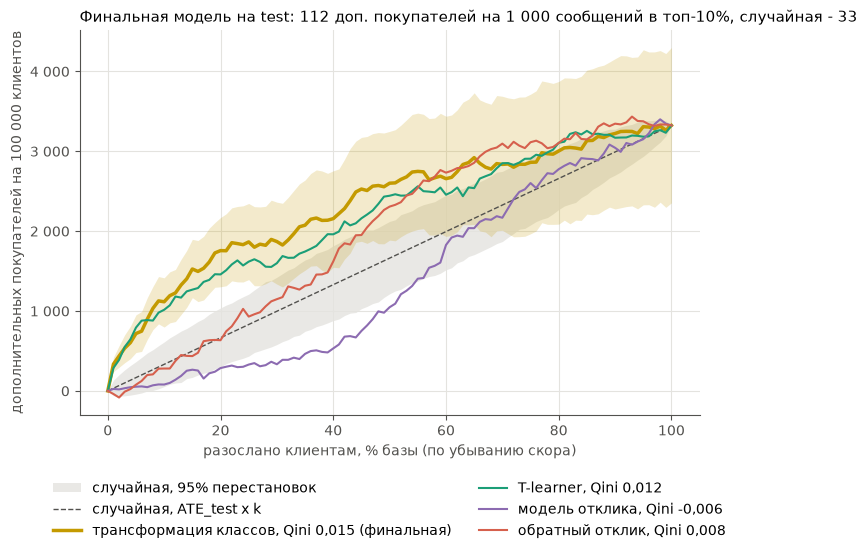

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
band = np.array(res["random"]["gain_band"]) * 1e5
ax.fill_between(shares * 100, band[0], band[1], color=plots.GRID, alpha=0.8, lw=0, label="случайная, 95% перестановок")
ax.plot([0, 100], [0, ate * 1e5], color=plots.INK, ls="--", lw=1, label="случайная, ATE_test x k")
for m in ORDER:
    r = res["models"][m]
    g = np.array(r["gain"]) * 1e5
    lw = 2.5 if m == FINAL else 1.5
    label = f"{plots.MODEL_NAMES[m]}, Qini {r['metrics']['qini']:.3f}".replace(".", ",")
    ax.plot(shares * 100, g, color=plots.MODEL_COLORS[m], lw=lw, label=label + (" (финальная)" if m == FINAL else ""))
    if m == FINAL:
        lo, hi = np.array(r["gain_ci"]) * 1e5
        ax.fill_between(shares * 100, lo, hi, color=plots.MODEL_COLORS[m], alpha=0.2, lw=0)
ax.set_xlabel("разослано клиентам, % базы (по убыванию скора)")
ax.set_ylabel("дополнительных покупателей на 100 000 клиентов")
plots.thousands(ax.yaxis)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
ax.set_title('Финальная модель на test: 112 доп. покупателей на 1 000 сообщений в топ-10%, случайная - 33')
plots.save(fig, "qini_test.png")
plt.show()

Кривая финальной модели выше коридора случайных перестановок примерно до 60% базы. Обратный отклик до ~35%
идёт внутри коридора и догоняет uplift-модели только к половине базы: его эффект размазан, а uplift-модели
собирают его в начале списка. Модель отклика ниже коридора примерно с 10 до 70%.

## Экономика

C - стоимость сообщения, V - ценность дополнительного покупателя; обе неизвестны. Прибыль в единицах V на 100 000
клиентов: 100 000 x (gain(k) - r x k), где r = C / V. Сетка r от 0 до 0,30 - допущение. Долю k для каждого r выбираю
на valid, прибыль при ней - на test. Рассылка всем безубыточна при r = ATE.

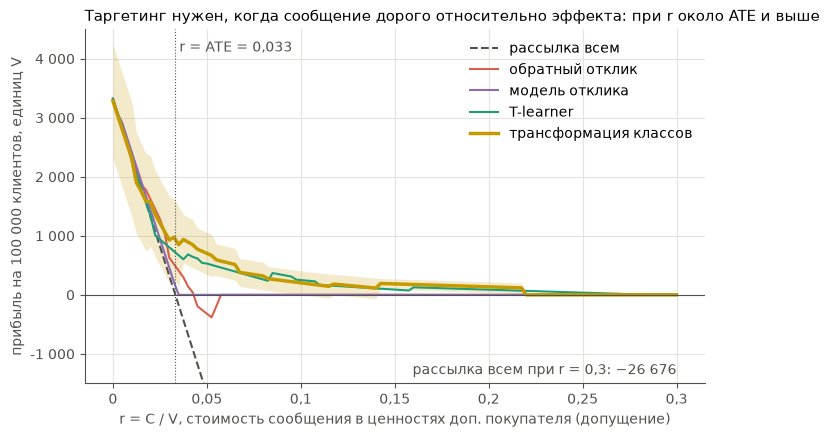

In [5]:
econ = res["economics"]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(r_grid, econ["send_all"]["profit"], color=plots.INK, lw=1.5, ls="--", label="рассылка всем")
for m in ["inverse_response", "response", "t_learner", FINAL]:
    lw = 2.5 if m == FINAL else 1.5
    ax.plot(r_grid, econ[m]["profit"], color=plots.MODEL_COLORS[m], lw=lw, label=plots.MODEL_NAMES[m])
lo, hi = econ[FINAL]["profit_ci"]
ax.fill_between(r_grid, lo, hi, color=plots.MODEL_COLORS[FINAL], alpha=0.2, lw=0)
ax.axhline(0, color=plots.INK, lw=0.8)
ax.axvline(ate, color=plots.INK, lw=0.8, ls=":")
ax.set_ylim(-1500, 4500)
ax.text(ate, 4300, f" r = ATE = {ate:.3f}".replace(".", ","), color=plots.INK, va="top")
loss = f"{econ['send_all']['profit'][-1]:,.0f}".replace(",", " ").replace("-", "−")
ax.text(0.30, -1400, f"рассылка всем при r = 0,3: {loss}",
        color=plots.INK, ha="right", va="bottom")
ax.set_xlabel("r = C / V, стоимость сообщения в ценностях доп. покупателя (допущение)")
ax.set_ylabel("прибыль на 100 000 клиентов, единиц V")
plots.decimal_comma(ax.xaxis)
plots.thousands(ax.yaxis)
ax.legend(loc="upper right")
ax.set_title('Таргетинг нужен, когда сообщение дорого относительно эффекта: при r около ATE и выше')
plots.save(fig, "economics_test.png")
plt.show()

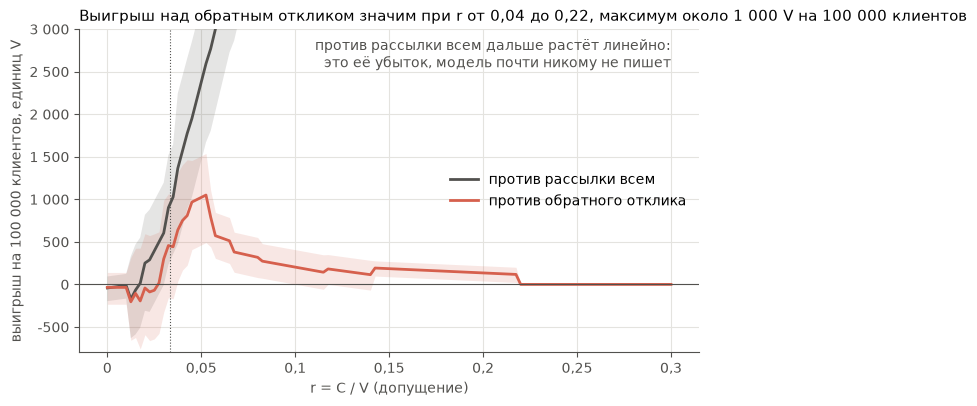

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, label, color in [("gain_vs_send_all", "против рассылки всем", plots.INK),
                           ("gain_vs_inverse_response", "против обратного отклика", plots.MODEL_COLORS["inverse_response"])]:
    g = econ[name]
    ax.plot(r_grid, g["estimate"], color=color, lw=2, label=label)
    ax.fill_between(r_grid, g["ci"][0], g["ci"][1], color=color, alpha=0.15, lw=0)
ax.axhline(0, color=plots.INK, lw=0.8)
ax.axvline(ate, color=plots.INK, lw=0.8, ls=":")
ax.set_ylim(-800, 3000)
ax.text(0.30, 2900, "против рассылки всем дальше растёт линейно:\nэто её убыток, модель почти никому не пишет",
        color=plots.INK, ha="right", va="top")
ax.set_xlabel("r = C / V (допущение)")
ax.set_ylabel("выигрыш на 100 000 клиентов, единиц V")
plots.decimal_comma(ax.xaxis)
plots.thousands(ax.yaxis)
ax.legend(loc="center right")
ax.set_title('Выигрыш над обратным откликом значим при r от 0,04 до 0,22, максимум около 1 000 V на 100 000 клиентов')
plots.save(fig, "gain_vs_r_test.png")
plt.show()

In [7]:
picks = [0.0, 0.01, 0.02, round(ate, 4), 0.05, 0.1, 0.2, 0.3]
rows = []
for r in picks:
    i = int(np.argmin(np.abs(r_grid - r)))
    row = {"r": r_grid[i]}
    for m in [FINAL, "inverse_response"]:
        row[f"k, {plots.MODEL_NAMES[m]}"] = econ[m]["share_chosen_on_valid"][i]
        row[f"прибыль, {plots.MODEL_NAMES[m]}"] = round(econ[m]["profit"][i])
    row["прибыль, рассылка всем"] = round(econ["send_all"]["profit"][i])
    for name in ["gain_vs_send_all", "gain_vs_inverse_response"]:
        g = econ[name]
        row[name] = f"{g['estimate'][i]:+.0f} ({g['ci'][0][i]:+.0f} ... {g['ci'][1][i]:+.0f})"
    rows.append(row)
pd.DataFrame(rows).set_index("r")

,"k, трансформация классов","прибыль, трансформация классов","k, обратный отклик","прибыль, обратный отклик","прибыль, рассылка всем",gain_vs_send_all,gain_vs_inverse_response
r,,,,,,,
0.0000,0.97,3282,0.97,3317,3324,-42 (-197 ... +93),-35 (-233 ... +141)
0.0100,0.97,2312,0.97,2347,2324,-12 (-167 ... +123),-35 (-233 ... +141)
0.0200,0.63,1575,0.66,1617,1324,+251 (-310 ... +818),-42 (-591 ... +596)
0.0325,0.50,975,0.44,518,74,+901 (+232 ... +1519),+457 (-154 ... +1065)
0.0500,0.14,703,0.25,-320,-1676,+2379 (+1455 ... +3282),+1023 (+464 ... +1511)
0.1000,0.04,203,0.00,0,-6676,+6879 (+5937 ... +7840),+203 (+2 ... +408)
0.2000,0.01,135,0.00,0,-16676,+16811 (+15840 ... +17781),+135 (+40 ... +219)
0.3000,0.00,0,0.00,0,-26676,+26676 (+25701 ... +27646),+0 (+0 ... +0)


- При r до 0,01 финальная модель выбирает 97% базы и от рассылки всем не отличается: -42 (-197 ... +93) единиц V
  на 100 000 клиентов при r = 0. От 0,0125 до 0,03 она пишет 58-72% базы, но выигрыш над рассылкой всем
  ещё не значим.
- При r около ATE (0,0325) рассылка всем выходит в ноль (+74), а финальная модель пишет половине базы и получает
  975: выигрыш +901 (+232 ... +1 519), с этого r он значим. Против обратного отклика здесь +457 (-154 ... +1 065) - не значимо.
- При r = 0,05 финальная модель пишет 14% базы и получает +703, обратный отклик по доле, выбранной на valid (25%),
  на test уходит в минус (-320): выигрыш +1 023 (+464 ... +1 511). Выигрыш над обратным откликом значим при r
  от 0,0375 до 0,2175 и максимален при r около 0,05 - около 1 050 V на 100 000 клиентов.
- При r от 0,1 модель пишет 1-4% базы, прибыль 130-200 V на 100 000 клиентов, при r от 0,25 - никому.

Вывод: uplift-таргетинг даёт деньги, когда сообщение стоит порядка среднего эффекта или дороже. Если сообщение
почти бесплатное, проще писать всем.

## Сегменты на valid (разведка)

Кого выбирают модели. Профиль топ-10% по финальной модели, топ-10% по модели отклика и всех клиентов valid.
Новых выборов здесь нет: модели и пороги те же.

In [8]:
X_valid, y_v, t_v = models.load("valid")
vs = pd.read_parquet(models.ARTIFACTS / "valid_scores.parquet").query(f"seed == {config.SEED}")
vs = vs.pivot(index="client_id", columns="model", values="score").loc[X_valid.index]


def top_mask(score, share=0.1):
    mask = np.zeros(len(score), dtype=bool)
    mask[np.argsort(score, kind="mergesort")[::-1][: int(len(score) * share)]] = True
    return mask


groups = {
    "топ-10% трансформации классов": top_mask(vs[FINAL].to_numpy()),
    "топ-10% модели отклика": top_mask(vs["response"].to_numpy()),
    "все клиенты valid": np.ones(len(X_valid), dtype=bool),
}
rows = {}
for name, mask in groups.items():
    g = X_valid[mask]
    yy, tt = y_v[mask], t_v[mask]
    d, lo, hi = stats.diff_props_ci(yy[tt == 1].sum(), (tt == 1).sum(), yy[tt == 0].sum(), (tt == 0).sum())
    rows[name] = {
        "клиентов": int(mask.sum()),
        "дней с последней покупки, медиана": g.days_since_last.median(),
        "чеков за историю, медиана": g.n_trn_all.median(),
        "сумма за историю, руб., медиана": g.sum_all.median(),
        "давность карты, дней, медиана": g.card_age_days.median(),
        "доля чеков со списанием, среднее": g.share_spend_all.mean(),
        "возраст, медиана": g.age.median(),
        "пол F": (g.gender == "F").mean(),
        "пол M": (g.gender == "M").mean(),
        "пол U": (g.gender == "U").mean(),
        "купили, treatment": yy[tt == 1].mean(),
        "купили, control": yy[tt == 0].mean(),
        "uplift, п.п.": f"{d * 100:.1f} ({lo * 100:.1f} ... {hi * 100:.1f})",
    }
pd.DataFrame(rows).round(3)

,топ-10% трансформации классов,топ-10% модели отклика,все клиенты valid
клиентов,4000,4000,40008
"дней с последней покупки, медиана",5.0,0.0,4.0
"чеков за историю, медиана",10.0,51.0,15.0
"сумма за историю, руб., медиана",2834.0,14985.76,6097.025
"давность карты, дней, медиана",273.0,554.0,487.0
"доля чеков со списанием, среднее",0.148317,0.047998,0.071116
"возраст, медиана",58.0,48.0,45.0
пол F,0.39825,0.42725,0.369176
пол M,0.143,0.1755,0.167591
пол U,0.45875,0.39725,0.463232


Топ-10% финальной модели - не самые активные клиенты: медиана 10 чеков против 15 у всех, сумма 2 834 руб.
против 6 097, карта моложе (273 дня против 487), старше по возрасту (58 лет против 45) и вдвое чаще списывают
баллы (14,8% чеков против 7,1%). Наблюдаемый uplift в этой группе 9,6 п.п. (6,5 ... 12,6), в control покупает 51%.
Топ-10% модели отклика - противоположность: покупали в последний день истории, 51 чек, 15 тысяч руб., в control
покупает 95%, uplift 1,0 п.п. (-0,3 ... +2,3). Почему модель выбирает именно таких клиентов, по этим данным
не установить; любые объяснения вроде «чувствительны к баллам» - гипотезы для отдельного теста.

Простой понятный сегмент для сравнения с моделью - давность последней покупки. Делю valid на децили по
`days_since_last` (одинаковые значения не разрываю, поэтому групп меньше 10) и в каждой считаю наблюдаемый uplift.

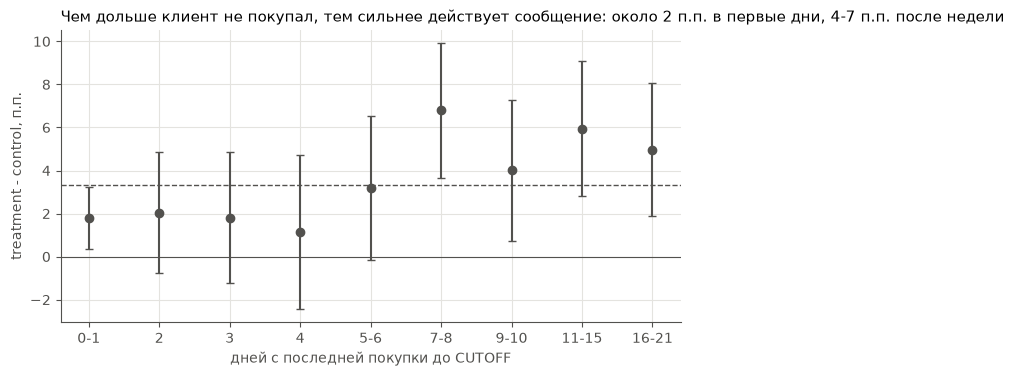

,клиентов,"купили, treatment","купили, control",uplift_pp,lo_pp,hi_pp
bin,,,,,,
"(-0.001, 1.0]",11478,0.816,0.798,1.797,0.354,3.241
"(1.0, 2.0]",3724,0.756,0.735,2.049,-0.749,4.847
"(2.0, 3.0]",3688,0.678,0.660,1.809,-1.228,4.845
"(3.0, 4.0]",2740,0.649,0.638,1.145,-2.443,4.733
"(4.0, 6.0]",3341,0.599,0.567,3.168,-0.174,6.510
"(6.0, 8.0]",3915,0.548,0.480,6.790,3.665,9.915
"(8.0, 10.0]",3541,0.457,0.416,4.012,0.748,7.277
"(10.0, 15.0]",3878,0.472,0.412,5.951,2.831,9.072
"(15.0, 21.0]",3703,0.380,0.330,4.965,1.887,8.044


In [9]:
bins = pd.qcut(X_valid.days_since_last, 10, duplicates="drop")
df = pd.DataFrame({"bin": bins.to_numpy(), "y": y_v, "t": t_v})
g = df.groupby(["bin", "t"], observed=True).y.agg(["sum", "count"]).unstack("t")
d, lo, hi = stats.diff_props_ci(g[("sum", 1)], g[("count", 1)], g[("sum", 0)], g[("count", 0)])
recency = pd.DataFrame({
    "клиентов": g[("count", 1)] + g[("count", 0)],
    "купили, treatment": g[("sum", 1)] / g[("count", 1)],
    "купили, control": g[("sum", 0)] / g[("count", 0)],
    "uplift": d, "lo": lo, "hi": hi,
})
def bin_label(b, first):
    lo, hi = (0 if first else int(np.floor(b.left)) + 1), int(b.right)
    return str(hi) if lo == hi else f"{lo}-{hi}"


labels = [bin_label(b, i == 0) for i, b in enumerate(recency.index)]

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(recency))
ax.errorbar(x, recency.uplift * 100, yerr=[(recency.uplift - recency.lo) * 100, (recency.hi - recency.uplift) * 100],
            fmt="o", color=plots.INK, capsize=3)
ax.axhline(y_v[t_v == 1].mean() * 100 - y_v[t_v == 0].mean() * 100, color=plots.INK, ls="--", lw=1)
ax.axhline(0, color=plots.INK, lw=0.8)
ax.set_xticks(x, labels)
ax.set_xlabel("дней с последней покупки до CUTOFF")
ax.set_ylabel("treatment - control, п.п.")
plots.decimal_comma(ax.yaxis)
ax.set_title('Чем дольше клиент не покупал, тем сильнее действует сообщение: около 2 п.п. в первые дни, 4-7 п.п. после недели')
plots.save(fig, "recency_uplift_valid.png")
plt.show()
recency.assign(uplift_pp=lambda d: d.uplift * 100, lo_pp=lambda d: d.lo * 100, hi_pp=lambda d: d.hi * 100)[
    ["клиентов", "купили, treatment", "купили, control", "uplift_pp", "lo_pp", "hi_pp"]].round(3)

Наблюдаемый uplift растёт с давностью последней покупки: +1,8 п.п. (0,4 ... 3,2) у покупавших в последние два дня
истории (0-1 день до CUTOFF), 1-3 п.п. при 2-6 днях и 4-7 п.п. у тех, кто не покупал неделю и больше (+6,8 при 7-8 днях, +5,0 при 16-21).
Это то же, что делает обратный отклик: писать тем, кто реже покупает. Простое правило «не покупал неделю» даёт
около 5 п.п. против 3,3 в среднем, но не 9,6, как верхний дециль модели.

## Итоги

- На test финальная модель (трансформация классов, seed 42) обгоняет случайную рассылку: Qini 0,015
  (0,009 ... 0,022), 112 дополнительных покупателей на 1 000 сообщений в топ-10% против 33.
- Модель отклика хуже случайной рассылки и на valid, и на test: она пишет тем, кто купит и без сообщения.
- Обратный отклик - сильный простой бейзлайн. Модель обгоняет его по uplift@10/20/30, но не по Qini:
  её добавка - в начале списка.
- T-learner и трансформация классов на test не различаются.
- Экономика: при r ниже ATE выигрыш над рассылкой всем не значим; с r около ATE таргетинг значимо выгоднее
  рассылки всем, при r от 0,0375 до 0,2175 - и обратного отклика. Цифры прибыли - в единицах V при допущении r = C / V.